# **Step 1: Dataset Selection**

**Dataset Title:** PhiUSIIL Phishing URL Dataset

**Source:** UCI Machine Learning Repository
https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset

**Description:**
This dataset has 235,795 website URLs: 134,850 legitimate and 100,945 phishing. For each URL,
there are 54 features. Some come from the URL itself, like its length and the number of digits
and special characters. Others come from the webpage, like whether it uses HTTPS, has a title,
or has a password field. The target column is `label`, where 1 means legitimate and 0 means phishing.

**Why I selected it:**
- I worked on this project in October, which is Cybersecurity Awareness Month. Phishing is one
  of the most common cyber threats, so I wanted my analysis to help people understand how
  phishing websites look different from real ones.
- The dataset is large and recent, and it has a clear target, so it is easy to compare the two groups.
- It has different types of features (binary, numbers and text), which gives a lot to explore
  in the EDA.

# **Step 2: Problem Definition**

## What is the dataset about?
Phishing websites copy real websites to trick people into giving their passwords or bank
details. This dataset describes real websites, and each one is labeled as phishing or
legitimate. In this project, I want to find out what makes phishing websites different, and
which signs can help people spot them.

## Main questions to explore
1. **Class distribution:** How many phishing and legitimate websites are there? Is the data balanced?
2. **URL structure:** Are phishing URLs longer? Do they have more digits, special characters
   or subdomains?
3. **Security indicators:** Do phishing websites use HTTPS? How often do they use an IP address
   instead of a domain name, or hide characters in the URL?
4. **Page content:** Are phishing pages smaller and simpler? Do they have a title, a favicon,
   a description or copyright information?
5. **Sensitive elements:** Do phishing pages have more password fields, hidden fields, or
   words like "bank", "pay" and "crypto"?
6. **Top-level domains:** Which endings (`.com`, `.org`, `.app`, ...) have the highest share of phishing websites?
7. **Key features:** Which features are most related to the label?

## Expected insights
Before starting the analysis, I expected that:
- Phishing URLs will be **longer**, with more digits and special characters.
- Legitimate websites will almost **always use HTTPS**, while many phishing websites will not.
- Phishing pages will be **smaller and simpler**, because they are usually made quickly and
  removed fast.
- **Trust signals** like copyright info, social media links and a description will be much
  more common on legitimate websites.
- Some TLDs will have a much higher share of phishing than others.
- A few features will separate the two groups very clearly.

# **Step 3: Data Loading & Structure**
In this step I load the data and check its structure: size, column types, statistics,
text values, missing values and duplicates.

### 3.1 Import libraries

In [1]:
%pip install ucimlrepo -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)

### 3.2 Load the dataset

In [3]:
phiusiil = fetch_ucirepo(id=967)

df = pd.concat([phiusiil.data.features, phiusiil.data.targets], axis=1)

### 3.3 A glance at the data

In [4]:
df.head()

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,0.061933,3,1,0,0,0.0,18,0.581,0,0.0,0,0,0,1,0.032,1,558,9381,1,à¸‚à¹ˆà¸²à¸§à¸ªà¸” à¸‚à¹ˆà¸²à¸§à¸§à¸±à¸™à¸™à¸µ...,0.000000,0.000000,0,1,1,0,0,0,0,1,0,0,1,1,0,1,0,0,1,34,20,28,119,0,124,1
1,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,0.050207,2,1,0,0,0.0,9,0.391,0,0.0,0,0,0,2,0.087,1,618,9381,1,johannes gutenberg-universitÃ¤t mainz,55.555556,55.555556,1,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,1,50,9,8,39,0,217,1
2,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,0.064129,2,2,0,0,0.0,15,0.517,0,0.0,0,0,0,2,0.069,1,467,682,1,voice fm southampton,46.666667,46.666667,0,1,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,10,2,7,42,2,5,1
3,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,0.057606,3,1,0,0,0.0,13,0.500,0,0.0,0,0,0,1,0.038,1,6356,26824,1,home page: seminars in fetal and neonatal medi...,0.000000,0.000000,0,1,1,0,0,0,1,12,0,1,1,1,0,0,1,1,1,3,27,15,22,1,31,1
4,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,0.059441,3,1,0,0,0.0,20,0.606,0,0.0,0,0,0,1,0.030,1,6089,28404,1,fundaciÃ³n rewilding argentina,100.000000,100.000000,0,1,1,1,1,1,0,2,0,1,1,1,0,1,1,0,1,244,15,34,72,1,85,1


In [5]:
# random rows, to also see some phishing examples
df.sample(5, random_state=42)

,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,URLCharProb,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,ObfuscationRatio,NoOfLettersInURL,LetterRatioInURL,NoOfDegitsInURL,DegitRatioInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,SpacialCharRatioInURL,IsHTTPS,LineOfCode,LargestLineLength,HasTitle,Title,DomainTitleMatchScore,URLTitleMatchScore,HasFavicon,Robots,IsResponsive,NoOfURLRedirect,NoOfSelfRedirect,HasDescription,NoOfPopup,NoOfiFrame,HasExternalFormSubmit,HasSocialNet,HasSubmitButton,HasHiddenFields,HasPasswordField,Bank,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
136221,https://www.northcm.ac.th,24,www.northcm.ac.th,17,0,th,100.000000,0.800000,0.000510,0.064490,2,2,0,0,0.0,10,0.417,0,0.000,0,0,0,2,0.083,1,999,457,1,norhcmac,0.0,0.0,1,0,1,0,0,1,0,5,0,1,1,1,0,0,0,0,1,47,3,4,69,7,115,1
56609,https://unitedmartialartscenters.com/at0/mygov...,59,unitedmartialartscenters.com,28,0,com,33.522664,1.000000,0.522907,0.060027,3,0,0,0,0.0,45,0.763,1,0.017,0,0,0,5,0.085,1,116,226,1,unitedmartialartscentersat0mygovpersonalhtm,0.0,0.0,1,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,1,0,2,0,0,0,1,0
46393,https://email.mail1.onesignal.os.tc/c/ejwcz02u...,385,email.mail1.onesignal.os.tc,27,0,tc,3.199329,0.458333,0.000046,0.034325,2,3,0,0,0.0,302,0.784,51,0.132,0,0,0,24,0.062,1,14,393,1,emailmail1onesignaloscejwcz02untamqohvwmwoczwf...,0.0,0.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0
129746,http://uqr.to/1il1z,19,uqr.to,6,0,to,53.846154,1.000000,0.000896,0.036850,2,0,0,0,0.0,8,0.421,2,0.105,0,0,0,2,0.105,0,9,70,1,uqr1il1z,0.0,100.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0
131464,https://www.woolworthsrewards.com.au,35,www.woolworthsrewards.com.au,28,0,au,100.000000,0.857143,0.010086,0.060894,2,2,0,0,0.0,21,0.600,0,0.000,0,0,0,2,0.057,1,1213,14983,1,woolworthsrewrdscom,0.0,0.0,1,0,1,1,1,1,0,3,0,1,0,1,1,1,1,0,1,33,7,8,15,0,2,1


### 3.4 Shape

In [6]:
print(f"Shape: {df.shape}\n")
print(f"There are {df.shape[0]:,} rows (websites)")
print(f"There are {df.shape[1]} columns: {df.shape[1]-1} features + 1 target (label)")

Shape: (235795, 55)

There are 235,795 rows (websites)
There are 55 columns: 54 features + 1 target (label)


### 3.5 Data types

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235795 entries, 0 to 235794
Data columns (total 55 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   URL                         235795 non-null  object 
 1   URLLength                   235795 non-null  int64  
 2   Domain                      235795 non-null  object 
 3   DomainLength                235795 non-null  int64  
 4   IsDomainIP                  235795 non-null  int64  
 5   TLD                         235795 non-null  object 
 6   URLSimilarityIndex          235795 non-null  float64
 7   CharContinuationRate        235795 non-null  float64
 8   TLDLegitimateProb           235795 non-null  float64
 9   URLCharProb                 235795 non-null  float64
 10  TLDLength                   235795 non-null  int64  
 11  NoOfSubDomain               235795 non-null  int64  
 12  HasObfuscation              235795 non-null  int64  
 13  NoOfObfuscated

In [8]:
binary_cols = [col for col in df.columns if df[col].nunique() == 2]
print(len(binary_cols), "binary columns:")
print(binary_cols)

20 binary columns:
['IsDomainIP', 'HasObfuscation', 'IsHTTPS', 'HasTitle', 'HasFavicon', 'Robots', 'IsResponsive', 'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton', 'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto', 'HasCopyrightInfo', 'label']


### 3.6 Data dictionary


The 55 columns are grouped by what they describe. The same groups are used in the EDA (Step 5).
Columns marked with * are renamed in Step 4.4. Descriptions of the derived scores follow the
dataset's documentation.

#### 1. Identifiers (text)
| Column | Type | Description |
|---|---|---|
| `URL` | Text | The full web address of the website |
| `Domain` | Text | The domain part of the URL (for example, `www.google.com`) |
| `TLD` | Text | The last part of the domain (for example, `com`, `org`, `uk`) |

#### 2. URL structure (explored in 5.4)
| Column | Type | Description |
|---|---|---|
| `URLLength` | Count | Number of characters in the URL |
| `DomainLength` | Count | Number of characters in the domain |
| `TLDLength` | Count | Number of characters in the TLD |
| `NoOfSubDomain` | Count | Number of subdomains (for example, `www` in `www.google.com`) |
| `NoOfLettersInURL` | Count | Number of letters in the URL |
| `LetterRatioInURL` | Ratio | Letters divided by URL length |
| `NoOfDegitsInURL` * | Count | Number of digits in the URL |
| `DegitRatioInURL` * | Ratio | Digits divided by URL length |
| `NoOfEqualsInURL` | Count | Number of `=` signs in the URL |
| `NoOfQMarkInURL` | Count | Number of `?` signs in the URL |
| `NoOfAmpersandInURL` | Count | Number of `&` signs in the URL |
| `NoOfOtherSpecialCharsInURL` | Count | Number of other special characters in the URL |
| `SpacialCharRatioInURL` * | Ratio | Special characters divided by URL length |

#### 3. Security indicators (explored in 5.5)
| Column | Type | Description |
|---|---|---|
| `IsDomainIP` | Binary | 1 if the URL uses an IP address instead of a domain name |
| `IsHTTPS` | Binary | 1 if the website uses HTTPS (checked in Step 4.6) |
| `HasObfuscation` | Binary | 1 if the URL contains hidden (encoded) characters, such as `%20` |
| `NoOfObfuscatedChar` | Count | Number of encoded characters in the URL |
| `ObfuscationRatio` | Ratio | Encoded characters divided by URL length |

#### 4. Derived scores (explored in 5.11)
| Column | Type | Description |
|---|---|---|
| `URLSimilarityIndex` | Score (0–100) | How similar the URL is to a list of known legitimate URLs |
| `CharContinuationRate` | Ratio | How much of the URL is made of long runs of the same character type (letters, digits or symbols) |
| `TLDLegitimateProb` | Probability | How often the TLD appears among legitimate websites |
| `URLCharProb` | Probability | How common the URL's characters are in legitimate URLs |
| `DomainTitleMatchScore` | Score (0–100) | How similar the page title is to the domain |
| `URLTitleMatchScore` | Score (0–100) | How similar the page title is to the URL |

#### 5. Page size and structure (explored in 5.6 and 5.9)
| Column | Type | Description |
|---|---|---|
| `LineOfCode` * | Count | Number of lines in the page's source code |
| `LargestLineLength` | Count | Number of characters in the longest line of code |
| `NoOfImage` | Count | Number of images on the page |
| `NoOfCSS` | Count | Number of CSS (style) files |
| `NoOfJS` | Count | Number of JavaScript files |
| `NoOfSelfRef` | Count | Number of links to the same website |
| `NoOfEmptyRef` | Count | Number of empty links (links that go nowhere) |
| `NoOfExternalRef` | Count | Number of links to other websites |
| `NoOfiFrame` | Count | Number of iframes (other pages embedded inside the page) |
| `NoOfPopup` | Count | Number of pop-up windows |
| `NoOfURLRedirect` * | Binary | 1 if the page redirects to another URL |
| `NoOfSelfRedirect` * | Binary | 1 if the page redirects to another page on the same website |

#### 6. Trust signals (explored in 5.6)
| Column | Type | Description |
|---|---|---|
| `HasTitle` | Binary | 1 if the page has a title |
| `Title` | Text | The page title (cleaned in Step 4.1) |
| `HasFavicon` | Binary | 1 if the page has a favicon (the small icon in the browser tab) |
| `HasDescription` | Binary | 1 if the page has a description for search engines |
| `HasCopyrightInfo` | Binary | 1 if the page shows copyright information |
| `HasSocialNet` | Binary | 1 if the page links to social media |
| `IsResponsive` | Binary | 1 if the page adapts to mobile screens |
| `Robots` * | Binary | 1 if the website has a robots.txt file (instructions for search engines) |

#### 7. Sensitive elements (explored in 5.7)
| Column | Type | Description |
|---|---|---|
| `HasPasswordField` | Binary | 1 if the page has a password field |
| `HasHiddenFields` | Binary | 1 if the page has hidden form fields |
| `HasSubmitButton` | Binary | 1 if the page has a submit button |
| `HasExternalFormSubmit` | Binary | 1 if a form on the page sends data to another website |
| `Bank` * | Binary | 1 if the word "bank" appears on the page |
| `Pay` * | Binary | 1 if the word "pay" appears on the page |
| `Crypto` * | Binary | 1 if the word "crypto" appears on the page |

#### 8. Target
| Column | Type | Description |
|---|---|---|
| `label` | Binary | **1 = legitimate**, **0 = phishing** |

### 3.7 Summary statistics

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
URLLength,235795.0,34.573095,41.314153,13.000000,23.000000,27.000000,34.000000,6.097000e+03
DomainLength,235795.0,21.470396,9.150793,4.000000,16.000000,20.000000,24.000000,1.100000e+02
IsDomainIP,235795.0,0.002706,0.051946,0.000000,0.000000,0.000000,0.000000,1.000000e+00
URLSimilarityIndex,235795.0,78.430778,28.976055,0.155574,57.024793,100.000000,100.000000,1.000000e+02
CharContinuationRate,235795.0,0.845508,0.216632,0.000000,0.680000,1.000000,1.000000,1.000000e+00
TLDLegitimateProb,235795.0,0.260423,0.251628,0.000000,0.005977,0.079963,0.522907,5.229071e-01
URLCharProb,235795.0,0.055747,0.010587,0.001083,0.050747,0.057970,0.062875,9.082366e-02
TLDLength,235795.0,2.764456,0.599739,2.000000,2.000000,3.000000,3.000000,1.300000e+01
NoOfSubDomain,235795.0,1.164758,0.600969,0.000000,1.000000,1.000000,1.000000,1.000000e+01
HasObfuscation,235795.0,0.002057,0.045306,0.000000,0.000000,0.000000,0.000000,1.000000e+00


### 3.8 Text columns

Checking the most common values of each text column to look for placeholders or
unexpected values. `URL` is skipped here because it is almost unique (checked in 3.10 Duplicates).

In [10]:
for col in ["Domain", "TLD", "Title"]:
    print(col, "- unique values:", df[col].nunique())
    print(df[col].value_counts().head(5), "\n")

Domain - unique values: 220086
Domain
ipfs.io                         1197
docs.google.com                  526
mail.deliverylifesupport.com     370
cloudflare-ipfs.com              359
storageapi.fleek.co              318
Name: count, dtype: int64 

TLD - unique values: 695
TLD
com    112554
org     18793
net      7097
app      6508
uk       6395
Name: count, dtype: int64 

Title - unique values: 197874
Title
0                              32719
#NAME?                            21
65gfgfgfgfg4g4gblogspot?m=1       12
gov                               11
info-update-sucreeblogspot        10
Name: count, dtype: int64 



- `Title` shows two unexpected values: `"0"` (32,719) and `"#NAME?"` (21), which are not real
titles (studied in 3.9 Missing values).

- The top TLDs look normal, but a TLD should contain **only letters**, so I checked whether
any values break this rule:

In [11]:
not_letters = ~df["TLD"].str.isalpha()
print("TLD values that are not only letters:", not_letters.sum())
df.loc[not_letters, "TLD"].value_counts().head(10)

TLD values that are not only letters: 666


,count
TLD,
238,43
24,41
xn--p1ai,35
78,31
94,29
67,28
181,28
128,27
86,24


Three types of values break the rule:
- **Numbers** (for example, `238`): these URLs use an IP address instead of a domain name,
  so the last number of the IP was stored as the TLD.
- **Port numbers** (for example, `com:443`): some URLs include a port after the domain
  (`site.com:443`), and the port was stored as part of the TLD.
- **Punycode** (for example, `xn--p1ai`): the format used for TLDs written in non-Latin
  characters, such as the Russian `.рф`. These are real TLDs.

In [12]:
print("Numeric TLDs:", df.loc[not_letters, "TLD"].str.isdigit().sum())
print("TLDs with a port number:", df.loc[not_letters, "TLD"].str.contains(":").sum())
print("Punycode TLDs:", df.loc[not_letters, "TLD"].str.startswith("xn--").sum())

Numeric TLDs: 599
TLDs with a port number: 26
Punycode TLDs: 41


The numbers and port numbers are not real TLDs and will be handled in Data Cleaning.

### 3.9 Missing values

In [13]:
print("Total missing values:", df.isnull().sum().sum())
df.isnull().sum()

Total missing values: 0


,0
URL,0
URLLength,0
Domain,0
DomainLength,0
IsDomainIP,0
TLD,0
URLSimilarityIndex,0
CharContinuationRate,0
TLDLegitimateProb,0
URLCharProb,0


3.8 showed that `Title` contains `"0"`. To check whether it means "no title", I compared
it with `HasTitle`:

In [14]:
pd.crosstab(df["Title"] == "0", df["HasTitle"],
            rownames=['Title == "0"'], colnames=["HasTitle"])

HasTitle,0,1
"Title == ""0""",,
False,0,203076
True,32714,5


Every page with `HasTitle = 0` has `Title = "0"`, which confirms that `"0"` is a
placeholder for a missing title. Only 5 rows have `"0"` while `HasTitle = 1`.

### 3.10 Duplicates

In [15]:
print(f"Duplicate rows: {df.duplicated().sum()}")
print(f"Duplicate URLs: {df['URL'].duplicated().sum()}")

Duplicate rows: 0
Duplicate URLs: 425


In [16]:
# labels of all rows whose URL appears more than once
df[df["URL"].duplicated(keep=False)]["label"].value_counts()

,count
label,
0,850


### 3.11 Target variable

In [17]:
counts = df["label"].value_counts()
percent = (df["label"].value_counts(normalize=True) * 100).round(1)

pd.DataFrame({"count": counts, "percent": percent}).rename(index={0: "Phishing", 1: "Legitimate"})

,count,percent
label,,
Legitimate,134850,57.2
Phishing,100945,42.8


### 3.12 Observations


- The dataset has **235,795 rows and 55 columns**: 51 numerical and 4 text columns
  (`URL`, `Domain`, `TLD`, `Title`).
- Of the 50 numerical features, **19 are binary (0/1) flags** such as `IsHTTPS` and
  `HasPasswordField`, plus the binary target `label`. Two of them, `NoOfURLRedirect` and
  `NoOfSelfRedirect`, are named like counts but only contain 0 and 1.
- Although `df.isnull()` reports **no missing values**, the `Title` column contains
  **hidden missing values**: 32,719 pages store `"0"` instead of a real title, and 21 titles
  appear as `"#NAME?"`, an Excel formula error. These will be handled in Data Cleaning.
- The `TLD` column contains values that are not real TLDs: **599 numeric values** (the last
  number of an IP address) and **26 values with a port number** (for example, `com:443`).
  These will be handled in Data Cleaning.
- The target `label` is **1 = Legitimate (57.2%)** and **0 = Phishing (42.8%)**, so the
  classes are reasonably balanced.
- Several features are heavily right-skewed with extreme maximums: for example,
  `URLLength` has a median of 27 but a max of 6,097, and `LineOfCode` has a median of 429
  but a max of 442,666. These outliers will be explored in the EDA.
- There are **no fully duplicated rows**, but **425 URLs appear twice**. All 850 rows are
  phishing, so both copies always have the same label. The copies differ slightly in some
  features, such as `URLLength` (off by one character). These are studied in Data Cleaning.

# **Step 4: Data Cleaning**

All cleaning steps are applied to a copy of the original data, so the raw dataset stays unchanged.

In [18]:
df_clean = df.copy()
print("Starting shape:", df_clean.shape)

Starting shape: (235795, 55)


### 4.1 Handling hidden missing values
As shown in Step 3.8 & 3.9, `Title` stores missing titles as `"0"` (32,719 rows) and has 21
corrupted values (`"#NAME?"`).

I considered several options before deciding what to do:

1. **Delete the rows:** rejected. A missing title could itself be a sign of phishing, since
   phishing pages are often built quickly (explored in Step 5).
2. **Leave the values as they are:** the `Title` text is not used in the analysis, since
   `HasTitle` and the title-match scores already carry this information. However, the
   cleaned file is also used by the dashboard and by anyone who downloads it, where `"0"`
   would look like a real title. So the values were replaced to make their meaning clear.
3. **Fill in the 5 inconsistent rows manually** (`HasTitle = 1` but `Title = "0"`):
   rejected. Current titles may differ from those at collection time, and the title-match
   scores were calculated from `"0"`, so editing the title alone would make these rows
   inconsistent.

**Decision:**
- `"0"` where `HasTitle = 0` → `"No Title"`
- `"0"` where `HasTitle = 1`, and `"#NAME?"` (an Excel formula error) → `"Unknown Title"`,
  because a title exists but its value is unknown.

In [19]:
# 1. The page has a title, but it was stored as "0"
inconsistent = (df_clean["Title"] == "0") & (df_clean["HasTitle"] == 1)
df_clean.loc[inconsistent, "Title"] = "Unknown Title"

# 2. The page has no title
no_title = (df_clean["Title"] == "0") & (df_clean["HasTitle"] == 0)
df_clean.loc[no_title, "Title"] = "No Title"

# 3. The title was corrupted by Excel
excel_error = df_clean["Title"] == "#NAME?"
df_clean.loc[excel_error, "Title"] = "Unknown Title"

print("Inconsistent rows:", inconsistent.sum())
print("Pages without a title:", no_title.sum())
print("Titles corrupted by Excel:", excel_error.sum())
print("Remaining placeholders:", df_clean["Title"].isin(["0", "#NAME?"]).sum())

Inconsistent rows: 5
Pages without a title: 32714
Titles corrupted by Excel: 21
Remaining placeholders: 0


### 4.2 Handling URL duplicates
Step 3.10 showed 425 URLs that appear twice, all phishing with the same label in both copies.
They are not lookalike URLs: the URL text and all domain features are identical. Before
deleting anything, I checked whether each pair is really the same observation.

In [20]:
dup_rows = df_clean[df_clean["URL"].duplicated(keep=False)]
domain_cols = ["Domain", "DomainLength", "TLD", "TLDLength", "NoOfSubDomain"]

different_domain = dup_rows.groupby("URL")[domain_cols].nunique().gt(1).any(axis=1)
print("Pairs with different domain features:", different_domain.sum())

Pairs with different domain features: 0


**Check 1: Same page or a changed page?**
I compared the page-content features (`LineOfCode` to `NoOfExternalRef`). `Title` and `URLTitleMatchScore` were left out because they also change with the URL text
in these pairs.

In [21]:
print("Duplicated URLs:", dup_rows["URL"].nunique())

page_cols = df_clean.loc[:, "LineOfCode":"NoOfExternalRef"].columns.drop(["Title", "URLTitleMatchScore"])
page_changed = dup_rows.groupby("URL")[page_cols].nunique().gt(1).any(axis=1)

print("Same page content:", (~page_changed).sum())
print("Page content changed:", page_changed.sum())

Duplicated URLs: 425
Same page content: 351
Page content changed: 74


In **74 pairs** the page itself changed between the two collections (for example, an almost
empty page in one copy and a full phishing page with a password field in the other). These
are two different observations, so **both copies are kept**.

**Check 2: What differs in the 351 same-page pairs?**

In [22]:
same_page = dup_rows[dup_rows["URL"].isin(page_changed[~page_changed].index)]
length_gap = same_page.groupby("URL")["URLLength"].agg(lambda s: s.max() - s.min())

print("Pairs where URLLength differs by exactly 1:", (length_gap == 1).sum(), "of", len(length_gap))

Pairs where URLLength differs by exactly 1: 351 of 351


In [23]:
off_by_one = (df_clean["URL"].str.len() - df_clean["URLLength"]) == 1
print(f"Rows where URLLength is 1 less than the URL length: {off_by_one.mean() * 100:.0f}%")

Rows where URLLength is 1 less than the URL length: 79%


In every pair, one copy's URL features were calculated **without the last character** of the
URL. This also happens in 79% of all rows, including rows with no duplicate, so it comes from
how the features were extracted.

However, identical page content alone does not prove both copies are the same URL: phishers
often reuse the same template on many URLs. So I checked whether the shorter version (the URL
without its last character) could be a **real, different address**:
- Ends with `/`: `site.com/` and `site.com` are the same address → **same page**.
- Ends with `.php` or `.htm`: `.ph` and `.ht` are not real file types → **same page**.
- The last character is part of the domain: all domain features are identical → **same page**.
- Anything else (for example, `.html` → `.htm`): could be a different page → **kept**.

In [24]:
def can_be_another_page(url):
    # site.com/ and site.com are the same address
    if url.endswith("/"):
        return False
    # .ph and .ht are not real file types
    if url.endswith((".php", ".htm")):
        return False
    # the last character is part of the domain
    if "/" not in url.split("://")[1]:
        return False
    return True

same_page_urls = pd.Series(page_changed[~page_changed].index)
possible_other_page = same_page_urls.map(can_be_another_page)

print("Cannot be another page (true duplicates):", (~possible_other_page).sum())
print("Could be another page (kept):", possible_other_page.sum())

Cannot be another page (true duplicates): 286
Could be another page (kept): 65


**Decision:** remove the second copy of the **286 true duplicates**, and keep the 74 pairs
with a changed page and the 65 pairs that could be different pages.

**DISCLAIMER:** These rules are strong but not perfect. For example, `site.com/folder/` and `site.com/folder`
can technically be different addresses, although servers usually redirect one to the other.
Since the page content is identical in all 286 pairs, removing them has almost no effect
even in the worst case.

In [25]:
true_dup_urls = same_page_urls[~possible_other_page]
to_drop = df_clean["URL"].isin(true_dup_urls) & df_clean["URL"].duplicated(keep="first")

phish_before = df_clean[df_clean["label"] == 0]
df_clean = df_clean[~to_drop].reset_index(drop=True)

print("Rows removed:", to_drop.sum())
print("Rows now:", len(df_clean))
print("URLs still appearing twice:", df_clean["URL"].duplicated().sum())
df_clean["label"].value_counts().rename({0: "Phishing", 1: "Legitimate"})

Rows removed: 286
Rows now: 235509
URLs still appearing twice: 139


,count
label,
Legitimate,134850
Phishing,100659


In [26]:
check = ["URLLength", "IsHTTPS", "HasPasswordField", "LineOfCode"]
impact = pd.DataFrame({"Before": phish_before[check].mean(),
                       "After": df_clean[df_clean["label"] == 0][check].mean()})
impact["Change %"] = ((impact["After"] / impact["Before"] - 1) * 100).round(2)
impact.round(3)

,Before,After,Change %
URLLength,45.720,45.719,-0.00
IsHTTPS,0.492,0.492,-0.13
HasPasswordField,0.054,0.054,-0.66
LineOfCode,65.730,65.643,-0.13


Removing the 286 duplicates changes the phishing averages by less than 1%, so no important
information was lost.

### 4.3 Outliers
Step 3 showed that several features have extreme maximums. Before deciding whether to
remove them, I checked how many there are and whether any are errors.

In [27]:
num_cols = df_clean.select_dtypes(include="number").columns.drop("label")
continuous_cols = [c for c in num_cols if df_clean[c].nunique() > 2]   # binary columns cannot have outliers

any_outlier = pd.Series(False, index=df_clean.index)
for col in continuous_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    any_outlier |= (df_clean[col] < q1 - 1.5 * iqr) | (df_clean[col] > q3 + 1.5 * iqr)

print(f"Rows with at least one outlier (IQR rule): {any_outlier.sum():,} ({any_outlier.mean() * 100:.1f}%)")

Rows with at least one outlier (IQR rule): 165,924 (70.5%)


In [28]:
ratio_cols = [c for c in continuous_cols if c.endswith(("Ratio", "RatioInURL", "Rate", "Prob"))]
score_cols = ["URLSimilarityIndex", "URLTitleMatchScore", "DomainTitleMatchScore"]

print("Negative values:", (df_clean[num_cols] < 0).sum().sum())
print("Ratios outside 0-1:", ((df_clean[ratio_cols] < 0) | (df_clean[ratio_cols] > 1)).sum().sum())
print("Scores outside 0-100:", ((df_clean[score_cols] < 0) | (df_clean[score_cols] > 100)).sum().sum())
print("Domain longer than the URL:", (df_clean["DomainLength"] > df_clean["URLLength"]).sum())

Negative values: 0
Ratios outside 0-1: 0
Scores outside 0-100: 0
Domain longer than the URL: 0


In [29]:
zero_iqr = [c for c in continuous_cols if df_clean[c].quantile(0.25) == 0 and df_clean[c].quantile(0.75) == 0]
print("Features where Q1 = Q3 = 0:", len(zero_iqr))
print(zero_iqr)

Features where Q1 = Q3 = 0: 8
['NoOfObfuscatedChar', 'ObfuscationRatio', 'NoOfDegitsInURL', 'DegitRatioInURL', 'NoOfEqualsInURL', 'NoOfQMarkInURL', 'NoOfAmpersandInURL', 'NoOfPopup']


**Result and decision:**
- **70.5% of rows** have at least one outlier by the IQR rule, so removing them would delete
  most of the dataset. The rule is also misleading here: in 8 features, such as
  `NoOfDegitsInURL`, Q1 and Q3 are both 0, so any non-zero value counts as an outlier.
- **No impossible values** were found, so the outliers are real values, not errors.
- Extreme values are expected: phishing URLs are often very long, while large legitimate
  websites can have thousands of lines of code. Whether the outliers are linked to the label
  is explored in Step 5.

**Decision:** keep all outliers, and use log scales or limited axis ranges in the
visualizations.

### 4.4 Renaming columns
Some column names have spelling mistakes from the original dataset, and some do not
describe their values clearly.

I renamed 10 columns to make the analysis and the
dashboard easier to read:
- **Spelling fixes:** `Degit` → `Digit`, `Spacial` → `Special`.
- **Binary columns named like counts:** `NoOfURLRedirect` and `NoOfSelfRedirect` only
  contain 0 and 1, so they were renamed with `Has`.
- **Clearer names:** `LineOfCode` → `NoOfLinesOfCode`; `Bank`, `Pay` and `Crypto` are
  flags for whether these keywords appear on the page, and `Robots` shows whether the
  site has a robots.txt file.

In [30]:
rename_map = {
    # spelling fixes
    "NoOfDegitsInURL": "NoOfDigitsInURL",
    "DegitRatioInURL": "DigitRatioInURL",
    "SpacialCharRatioInURL": "SpecialCharRatioInURL",
    # binary columns named like counts
    "NoOfURLRedirect": "HasURLRedirect",
    "NoOfSelfRedirect": "HasSelfRedirect",
    # clearer names
    "LineOfCode": "NoOfLinesOfCode",
    "Robots": "HasRobots",
    "Bank": "HasBankKeyword",
    "Pay": "HasPayKeyword",
    "Crypto": "HasCryptoKeyword",
}

df_clean = df_clean.rename(columns=rename_map)
pd.DataFrame(rename_map.items(), columns=["Old name", "New name"])

,Old name,New name
0,NoOfDegitsInURL,NoOfDigitsInURL
1,DegitRatioInURL,DigitRatioInURL
2,SpacialCharRatioInURL,SpecialCharRatioInURL
3,NoOfURLRedirect,HasURLRedirect
4,NoOfSelfRedirect,HasSelfRedirect
5,LineOfCode,NoOfLinesOfCode
6,Robots,HasRobots
7,Bank,HasBankKeyword
8,Pay,HasPayKeyword
9,Crypto,HasCryptoKeyword


### 4.5 Fixing TLD values and adding a TLD type
Some `TLD` values are not real TLDs, so they were fixed, and a new `TLDType` column was added
to group all TLDs into 6 types.

As shown in Step 3.8, `TLD` contains three kinds of unexpected values:
- **Port numbers:** some URLs include a port after the domain (for example, `site.com:443`),
  and the port was stored as part of the TLD (`com:443`). The port was removed, so only the TLD (`com`) is kept. The port itself is still visible in the `URL` column.
- **IP addresses:** for URLs that use an IP address instead of a domain name, the last number
  of the IP is stored as the TLD (for example, `238`). These values were replaced with `"IP"`.
- **Punycode:** some values (for example, `xn--p1ai` for the Russian `.рф`) are TLDs written in
  non-Latin characters. These are real TLDs and were kept.

Port numbers are removed first, so IP addresses with a port (for example, `240:8087`) are also
detected as IP addresses.

The new `TLDType` column makes it possible to compare all TLDs, including rare ones, and to
use TLD type as a filter in the dashboard.

In [31]:
# 1. Remove port numbers (for example, "com:443" → "com")
has_port = df_clean["TLD"].str.contains(":")
print("TLD values with a port number:", has_port.sum())
df_clean["TLD"] = df_clean["TLD"].str.split(":").str[0]

# 2. Replace IP numbers with "IP"
is_ip = df_clean["TLD"].str.isdigit()
print("TLD values that are IP numbers:", is_ip.sum())
df_clean.loc[is_ip, "TLD"] = "IP"

TLD values with a port number: 26
TLD values that are IP numbers: 607


In [32]:
def tld_type(tld):
    if tld == "IP":
        return "IP address (no TLD)"
    if tld.startswith("xn--"):
        return "Non-Latin (Punycode)"
    if tld in ["gov", "edu", "mil", "int"]:
        return "Restricted"
    if tld in ["com", "org", "net", "info", "biz"]:
        return "Classic generic"
    if len(tld) == 2:
        return "Country code"
    return "New generic"

df_clean["TLDType"] = df_clean["TLD"].apply(tld_type)
df_clean["TLDType"].value_counts()

,count
TLDType,
Classic generic,140311
Country code,68925
New generic,22146
Restricted,3479
IP address (no TLD),607
Non-Latin (Punycode),41


### 4.6 Fixing `IsHTTPS`
`IsHTTPS` should show whether the URL uses the HTTPS protocol, which is set by how the URL
starts (`https://`). First, I checked that every URL starts with either `http://` or `https://`:

In [33]:
other = ~df_clean["URL"].str.startswith(("http://", "https://"))
print("URLs that start with neither:", other.sum())

URLs that start with neither: 0


Then I checked whether `IsHTTPS` matches how each URL starts:

In [34]:
http_urls = df_clean[df_clean["URL"].str.startswith("http://")]
contains_https = http_urls["URL"].str.contains("https")

pd.crosstab(contains_https, http_urls["IsHTTPS"],rownames=['http URL contains "https"'], colnames=["IsHTTPS"])

IsHTTPS,0,1
"http URL contains ""https""",,
False,51177,0
True,0,493


**Result:** 493 URLs that start with `http://` have `IsHTTPS = 1`, and every one of them
contains the word "https" somewhere else in the URL. This suggests `IsHTTPS` was calculated as
"the URL contains https anywhere" rather than "the URL starts with https://". For example:
- `http://43.134.167.94/servicelogin?continue=https://accounts.google.com`: the "https" is
  part of a redirect link, not the protocol of the site.
- `http://www.httpsbinance.com`: the word "https" was placed in the domain name itself,
  likely to make the site look secure.

All 493 are phishing websites, so this error makes some phishing sites look safer than they
are. I considered three options:
1. **Keep the column as it is:** the error affects only 0.2% of rows.
2. **Add a corrected column** next to the original: allows comparison, but adds a nearly
   identical column.
3. **Correct the column:** the original values are simply wrong for these rows, and HTTPS is
   one of the main features explored in this analysis.

**Decision:** correct `IsHTTPS` from the URL itself, so it is 1 only when the URL starts with `https://`.

In [35]:
phishing_share_before = (df_clean.loc[df_clean["IsHTTPS"] == 1, "label"] == 0).mean() * 100

wrong = df_clean["URL"].str.startswith("http://") & (df_clean["IsHTTPS"] == 1)
print("Rows with a wrong IsHTTPS value:", wrong.sum())

df_clean["IsHTTPS"] = df_clean["URL"].str.startswith("https://").astype(int)

still_wrong = df_clean["URL"].str.startswith("http://") & (df_clean["IsHTTPS"] == 1)
print("Rows still wrong:", still_wrong.sum())

Rows with a wrong IsHTTPS value: 493
Rows still wrong: 0


In [36]:
phishing_share_after = (df_clean.loc[df_clean["IsHTTPS"] == 1, "label"] == 0).mean() * 100

print(f"Share of phishing among HTTPS websites: {phishing_share_before:.1f}% → {phishing_share_after:.1f}%")

Share of phishing among HTTPS websites: 26.8% → 26.6%


The correction changes the results only slightly, but `IsHTTPS` now correctly reflects the
protocol of each URL.

### 4.7 Adding a readable label column
The target `label` uses 1 for legitimate and 0 for phishing, which is easy to mix up.
I added a `label_name` column with the text values, to make charts and the dashboard
easier to read. The original `label` column is kept for correlation analysis.

In [37]:
df_clean["label_name"] = df_clean["label"].map({0: "Phishing", 1: "Legitimate"})

pd.crosstab(df_clean["label"], df_clean["label_name"])

label_name,Legitimate,Phishing
label,,
0,0,100659
1,134850,0


### 4.8 Final check
A final check to confirm that every cleaning step worked and the dataset is ready for analysis.

In [38]:
print("Final shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Fully duplicated rows:", df_clean.duplicated().sum())
print("URLs appearing twice (kept on purpose):", df_clean["URL"].duplicated().sum())
print("Placeholder titles:", df_clean["Title"].isin(["0", "#NAME?"]).sum())
print("TLD values with a port or a number:", df_clean["TLD"].str.contains(r":|^\d+$").sum())
print("http URLs marked as HTTPS:", (df_clean["URL"].str.startswith("http://") & (df_clean["IsHTTPS"] == 1)).sum())

df_clean["label_name"].value_counts()

Final shape: (235509, 57)
Missing values: 0
Fully duplicated rows: 0
URLs appearing twice (kept on purpose): 139
Placeholder titles: 0
TLD values with a port or a number: 0
http URLs marked as HTTPS: 0


,count
label_name,
Legitimate,134850
Phishing,100659


### 4.9 Saving the cleaned data
The cleaned dataset is saved as a CSV file, which is used by the Streamlit dashboard.

In [39]:
df_clean.to_csv("phishing_clean.csv", index=False)
print(f"Saved phishing_clean.csv: {df_clean.shape[0]:,} rows × {df_clean.shape[1]} columns")

Saved phishing_clean.csv: 235,509 rows × 57 columns


In [40]:
from google.colab import files   # only works in Google Colab
files.download("phishing_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### 4.10 Cleaning summary

| Step | Finding | Action |
|---|---|---|
| Hidden missing values | `Title` stores missing titles as `"0"` and has 21 `"#NAME?"` errors | `"0"` → `"No Title"` (32,714); inconsistent and corrupted → `"Unknown Title"` (26) |
| Duplicates | 425 URLs appear twice, all phishing with the same label | 286 true duplicates removed; 139 pairs kept (page changed or could be a different page) |
| Outliers | 70.5% of rows have an IQR outlier; no impossible values | Kept (real values, explored in Step 5) |
| Renaming | Spelling mistakes and unclear names | 10 columns renamed |
| TLD values | 26 TLDs include a port number; 607 are IP numbers | Ports removed; IPs replaced with `"IP"`; added `TLDType` (6 types) |
| HTTPS flag | 493 `http://` URLs marked as HTTPS because "https" appears elsewhere in the URL | Corrected from the URL |
| New column | Label values 0/1 are easy to mix up | Added `label_name` |
| Data types | All columns already have suitable types | No conversion needed |

**Final dataset:** 235,509 rows × 57 columns, saved as `phishing_clean.csv`.

# **Step 5: Exploratory Data Analysis (EDA)**

### 5.0 Chart settings

All charts use the same colors: **orange for phishing** and **blue for legitimate** websites.

In [41]:
PALETTE = {"Phishing": "#eb6834", "Legitimate": "#2a78d6"}
ORDER = ["Phishing", "Legitimate"]
THOUSANDS = "{x:,.0f}"   # 100000 → 100,000
DIVERGING = "RdBu"       # red = linked to phishing, blue = linked to legitimate

sns.set_style("whitegrid")

## Univariate Analysis

### 5.1 Target distribution
**Question 1:** How many phishing and legitimate websites are there? Is the data balanced?

             Count  Percent
label_name                 
Phishing    100659     42.7
Legitimate  134850     57.3


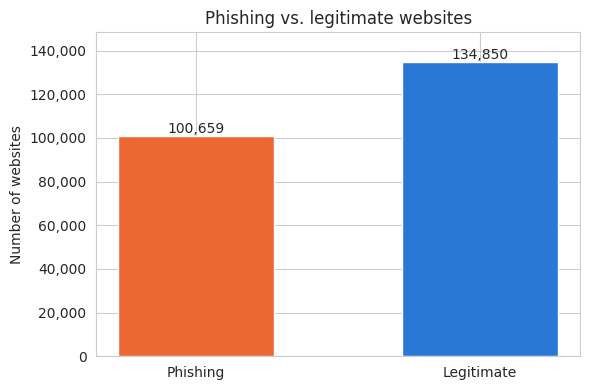

In [42]:
counts = df_clean["label_name"].value_counts()[ORDER]
percent = (counts / len(df_clean) * 100).round(1)
print(pd.DataFrame({"Count": counts, "Percent": percent}))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(ORDER, counts, color=[PALETTE[x] for x in ORDER], width=0.55)
ax.bar_label(bars, fmt="{:,.0f}")

ax.set_title("Phishing vs. legitimate websites")
ax.set_ylabel("Number of websites")
ax.yaxis.set_major_formatter(THOUSANDS)
ax.margins(y=0.1)
plt.tight_layout()
plt.show()

**Insight:** The dataset contains **100,659 phishing (42.7%)** and **134,850 legitimate (57.3%)** websites. The classes are **fairly balanced**, so neither class dominates the comparisons.

### 5.2 Numerical features
Before comparing the two classes, this chart shows how four key numerical features are distributed across all websites.

These features are heavily right-skewed (Step 3.12), so the x-axis uses a **log scale**.
Since some values are 0 and log(0) is undefined, 1 is added to every value before plotting.
The dashed line marks the median.

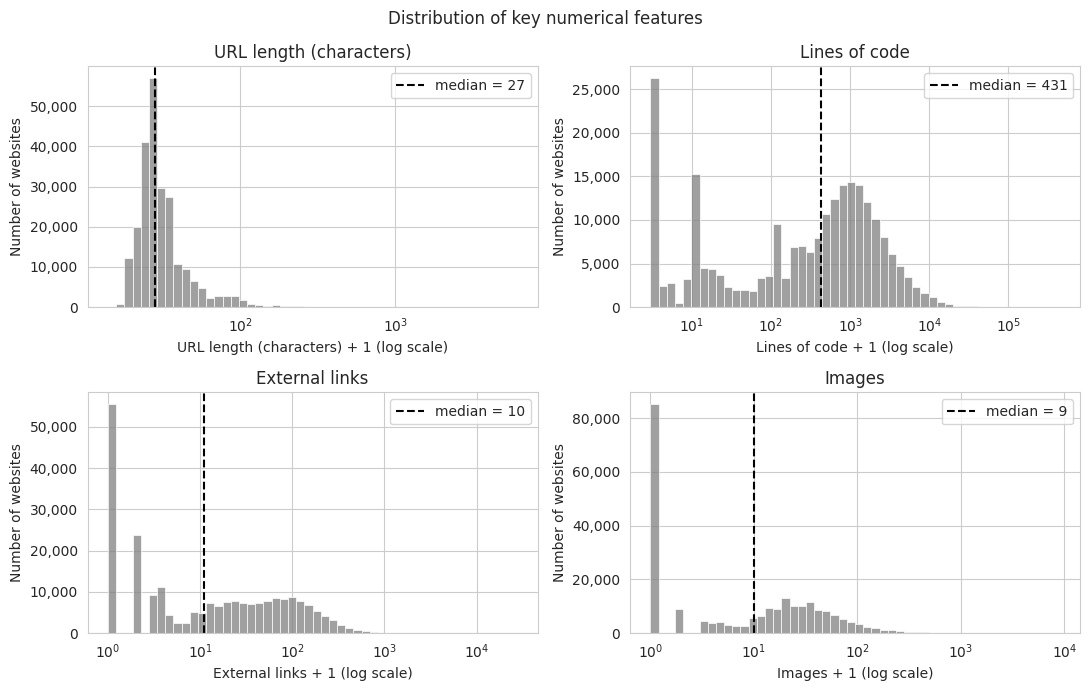

In [43]:
features = {"URLLength": "URL length (characters)",
            "NoOfLinesOfCode": "Lines of code",
            "NoOfExternalRef": "External links",
            "NoOfImage": "Images"}

fig, axes = plt.subplots(2, 2, figsize=(11, 7))

for ax, (col, label) in zip(axes.flat, features.items()):
    median = df_clean[col].median()
    # +1 so that websites with 0 can be shown on the log scale
    sns.histplot(df_clean[col] + 1, bins=50, log_scale=True, color="gray", ax=ax)
    ax.axvline(median + 1, color="black", linestyle="--", label=f"median = {median:,.0f}")
    ax.legend()
    ax.set_title(label)
    ax.set_xlabel(f"{label} + 1 (log scale)")
    ax.set_ylabel("Number of websites")
    ax.yaxis.set_major_formatter(THOUSANDS)

plt.suptitle("Distribution of key numerical features")
plt.tight_layout()
plt.show()

In [44]:
print("Share of websites with 0 (%):")
print((df_clean[list(features)] == 0).mean().mul(100).round(1))
print("\nPages with 20 lines of code or fewer:", round((df_clean["NoOfLinesOfCode"] <= 20).mean() * 100, 1), "%")

Share of websites with 0 (%):
URLLength           0.0
NoOfLinesOfCode     0.0
NoOfExternalRef    23.6
NoOfImage          36.2
dtype: float64

Pages with 20 lines of code or fewer: 26.4 %


**Insights:**
- **URL length** is concentrated around a median of 27 characters, with a long tail of very long URLs (up to 6,097 characters).
- **Lines of code has two peaks:** very small pages (26% have 20 lines or fewer) and pages around 1,000 lines. This suggests two types of pages, which are compared by label in Step 5.6.
- **External links and images** are 0 for many websites (24% and 36%), while others have hundreds or thousands.

### 5.3 Binary features
The dataset has 19 binary (0/1) features. This chart shows how common each one is
across all websites.

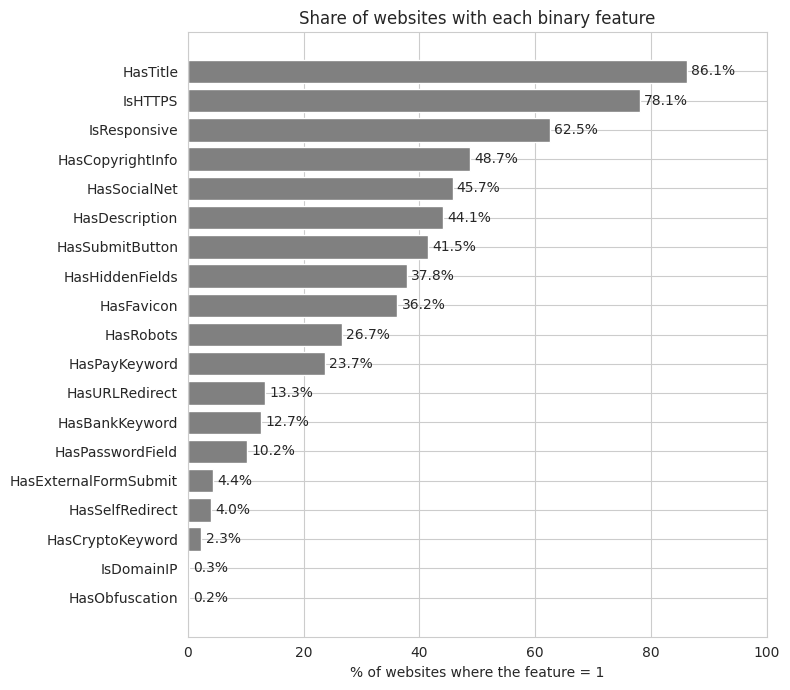

In [45]:
binary_features = [c for c in df_clean.select_dtypes(include="number").columns
                   if df_clean[c].nunique() == 2 and c != "label"]
share = (df_clean[binary_features].mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
bars = ax.barh(share.index, share, color="gray")
ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_title("Share of websites with each binary feature")
ax.set_xlabel("% of websites where the feature = 1")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

**Insights:**
- **Most common:** 86.1% of websites have a **title**, 78.1% use **HTTPS**, and 62.5% are **responsive** (adapt to mobile screens). Step 5.5 checks whether these differ between phishing and legitimate websites.
- **Sensitive elements are less common:** 10.2% of pages have a password field, 12.7% mention “bank”, and 23.7% mention “pay”.
- **Rare features:** only 0.3% of websites use an **IP address** as their domain, and 0.2% have
  **obfuscated characters**. Even if these features turn out to be strong signs of phishing,
  they apply to very few websites.

## Bivariate Analysis


### 5.4 URL structure
**Question 2:** Are phishing URLs longer? Do they have more digits, special characters or subdomains?

label_name
Legitimate    26.0
Phishing      34.0
Name: URLLength, dtype: float64


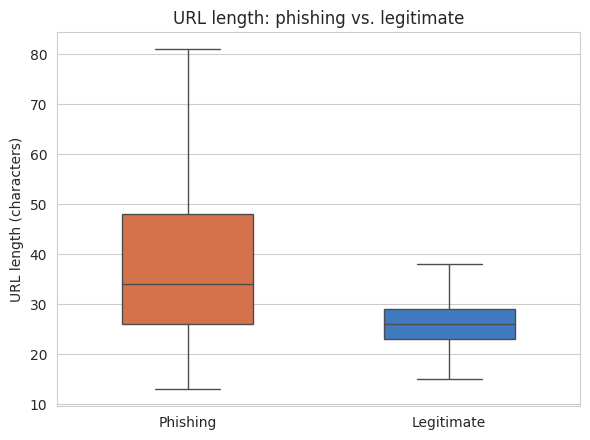

In [46]:
print(df_clean.groupby("label_name")["URLLength"].median())

fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=df_clean, x="label_name", y="URLLength", hue="label_name", order=ORDER,
            palette=PALETTE, legend=False, showfliers=False, width=0.5, ax=ax)
ax.set_title("URL length: phishing vs. legitimate")
ax.set_xlabel("")
ax.set_ylabel("URL length (characters)")
plt.tight_layout()
plt.show()

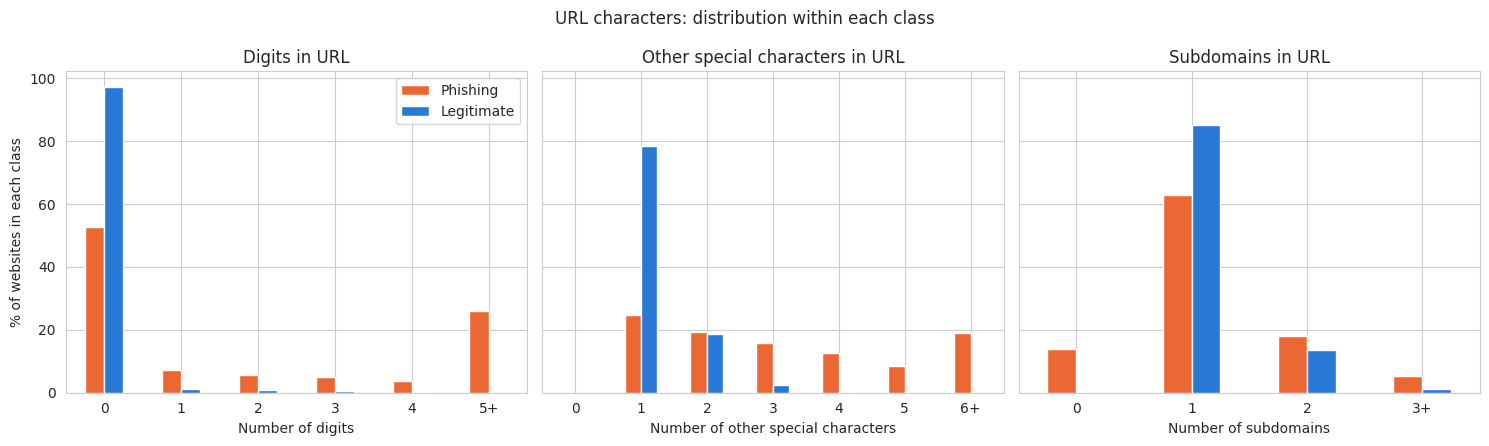

In [47]:
count_features = {"NoOfDigitsInURL": ("Digits", 5),
                  "NoOfOtherSpecialCharsInURL": ("Other special characters", 6),
                  "NoOfSubDomain": ("Subdomains", 3)}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, (col, (label, cap)) in zip(axes, count_features.items()):
    values = df_clean[col].clip(upper=cap)   # 5, 6, 7... all become 5 (shown as "5+")
    pct = pd.crosstab(values, df_clean["label_name"], normalize="columns")[ORDER] * 100
    pct = pct.rename(index={cap: f"{cap}+"})
    pct.plot(kind="bar", color=PALETTE, rot=0, legend=False, ax=ax)
    ax.set_title(f"{label} in URL")
    ax.set_xlabel(f"Number of {label.lower()}")

axes[0].set_ylabel("% of websites in each class")
axes[0].legend()
plt.suptitle("URL characters: distribution within each class")
plt.tight_layout()
plt.show()

In [48]:
is_legit = df_clean["label"] == 1
has_path = df_clean["URL"].str.split("://").str[1].str.contains("/")

print("Legitimate URLs that start with https://www.:", round(df_clean.loc[is_legit, "URL"].str.startswith("https://www.").mean() * 100, 1), "%")
print("Legitimate URLs with a path:", round(has_path[is_legit].mean() * 100, 1), "%")
print("Phishing URLs with a path:", round(has_path[~is_legit].mean() * 100, 1), "%")
print("Phishing URLs longer than 50 characters:", round((df_clean.loc[~is_legit, "URLLength"] > 50).mean() * 100, 1), "%")

Legitimate URLs that start with https://www.: 100.0 %
Legitimate URLs with a path: 0.0 %
Phishing URLs with a path: 59.8 %
Phishing URLs longer than 50 characters: 22.3 %


**Insights:**
- **Length:** phishing URLs are longer, with a median of **34** characters vs **26** for
  legitimate URLs, and much more spread out. **22%** of phishing URLs are longer than 50
  characters, compared to none of the legitimate ones.
- **Digits:** **97%** of legitimate URLs contain no digits, compared to **53%** of
  phishing URLs. A quarter of phishing URLs (**26%**) have 5 or more digits.
- **Special characters:** most legitimate URLs (**79%**) have just 1, while **19%** of
  phishing URLs have 6 or more.
- **Subdomains:** **14%** of phishing URLs have no subdomain, while every legitimate
  URL has at least one (`www`).

As expected in Step 2, phishing URLs are longer and contain more digits and special characters.

**Limitation:** every legitimate URL in this dataset is a homepage in the form
`https://www.domain`, with no path after the domain, while **60%** of phishing URLs
include a path. Part of these differences comes from how the legitimate URLs were
collected, not only from how phishers build URLs.

### 5.5 Security indicators
**Question 3:** Do phishing websites use HTTPS? How often do they use an IP address instead of a domain name, or hide characters in the URL?

For each indicator, the chart shows what share of the websites
with that indicator are phishing. I also checked **Punycode domains** (`xn--`), the format used for domains written with
non-Latin characters, which can be used for lookalike domains (homograph attacks).

                        Websites  % phishing  % of all phishing sites
Uses HTTP (no HTTPS)       51670       100.0                     51.3
Uses HTTPS                183839        26.6                     48.7
IP address as domain         637       100.0                      0.6
Obfuscated characters        485       100.0                      0.5
Punycode domain (xn--)       154       100.0                      0.2
Any of the last three       1273       100.0                      1.3


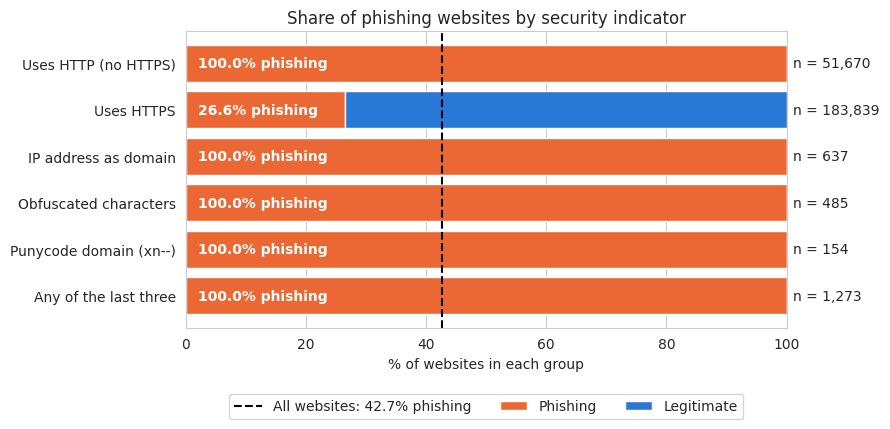

In [49]:
phishing = df_clean["label"] == 0
punycode = df_clean["URL"].str.contains("xn--")

groups = {"Uses HTTP (no HTTPS)":   df_clean["IsHTTPS"] == 0,
          "Uses HTTPS":             df_clean["IsHTTPS"] == 1,
          "IP address as domain":   df_clean["IsDomainIP"] == 1,
          "Obfuscated characters":  df_clean["HasObfuscation"] == 1,
          "Punycode domain (xn--)": punycode,
          "Any of the last three":  (df_clean["IsDomainIP"] == 1) | (df_clean["HasObfuscation"] == 1) | punycode}

security = pd.DataFrame({
    "Websites": [mask.sum() for mask in groups.values()],
    "% phishing": [phishing[mask].mean() * 100 for mask in groups.values()],
    "% of all phishing sites": [(mask & phishing).sum() / phishing.sum() * 100 for mask in groups.values()],
}, index=groups.keys()).round(1)
print(security)

chart = security[::-1]   # first group at the top

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(chart.index, chart["% phishing"], color=PALETTE["Phishing"], label="Phishing")
bars = ax.barh(chart.index, 100 - chart["% phishing"], left=chart["% phishing"],
               color=PALETTE["Legitimate"], label="Legitimate")
ax.bar_label(bars, labels=[f"n = {n:,}" for n in chart["Websites"]], padding=5)

for i, p in enumerate(chart["% phishing"]):
    ax.text(2, i, f"{p:.1f}% phishing", va="center", color="white", fontweight="bold")

ax.axvline(phishing.mean() * 100, color="black", linestyle="--",
           label=f"All websites: {phishing.mean() * 100:.1f}% phishing")
ax.set_xlim(0, 100)
ax.set_xlabel("% of websites in each group")
ax.set_title("Share of phishing websites by security indicator")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
plt.tight_layout()
plt.show()

**Insights:**
- **HTTP:** every website without HTTPS (**51,670**) is phishing.
- **HTTPS is not a guarantee of safety:** **26.6%** of websites that use HTTPS are still
  phishing, about 1 in 4, and almost half of all phishing websites (**49%**) use HTTPS.
  The padlock in the browser only means the connection is encrypted, not that the site
  is trustworthy.
- **IP addresses, obfuscated characters and Punycode domains** are **100%** phishing.
  These are strong warning signs, but they are rare: together they appear in only
  **1,273** websites (**0.5%**) and cover just **1.3%** of all phishing websites.

**Limitation:** legitimate websites always use HTTPS, but this is partly caused by how the
dataset was built: all legitimate URLs are homepages in the form `https://www.domain`
(see 5.4). So the 100% figure should not be read as "every safe website uses HTTPS".

### 5.6 Page content and trust signals
**Question 4:** Are phishing pages smaller and simpler? Do they have a title, a favicon, a description or copyright information?

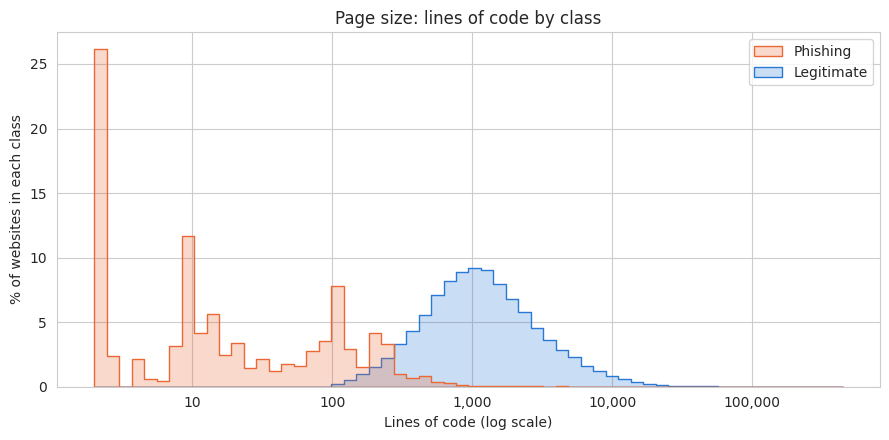

In [50]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(data=df_clean, x="NoOfLinesOfCode", hue="label_name", hue_order=ORDER,
             palette=PALETTE, log_scale=True, bins=60, stat="percent", common_norm=False,
             element="step", ax=ax)
ax.set_title("Page size: lines of code by class")
ax.set_xlabel("Lines of code (log scale)")
ax.set_ylabel("% of websites in each class")
ax.xaxis.set_major_formatter(THOUSANDS)
ax.get_legend().set_title("")
plt.tight_layout()
plt.show()

In [51]:
print(df_clean.groupby("label_name")["NoOfLinesOfCode"].describe()[["min", "25%", "50%", "75%"]])

small_pages = df_clean["NoOfLinesOfCode"] <= 20
print("\nPages with 20 lines of code or fewer:", small_pages.sum())
print("Share of them that are phishing:", (df_clean.loc[small_pages, "label"] == 0).mean() * 100)

              min    25%     50%     75%
label_name                              
Legitimate  102.0  613.0  1105.0  2088.0
Phishing      2.0    2.0    12.0    90.0

Pages with 20 lines of code or fewer: 62164
Share of them that are phishing: 100.0


**Insights:**
- The two peaks found in 5.2 are explained by the label: **the small pages are phishing and
  the large pages are mostly legitimate.** Phishing pages have a median of **12** lines of
  code, compared to **1,105** for legitimate pages.
- **62%** of phishing pages have 20 lines of code or fewer, and **every** page this small is
  phishing. Many phishing pages are minimal, probably because they are built quickly or are
  just a login form.

As expected in Step 2, phishing pages are smaller and simpler.

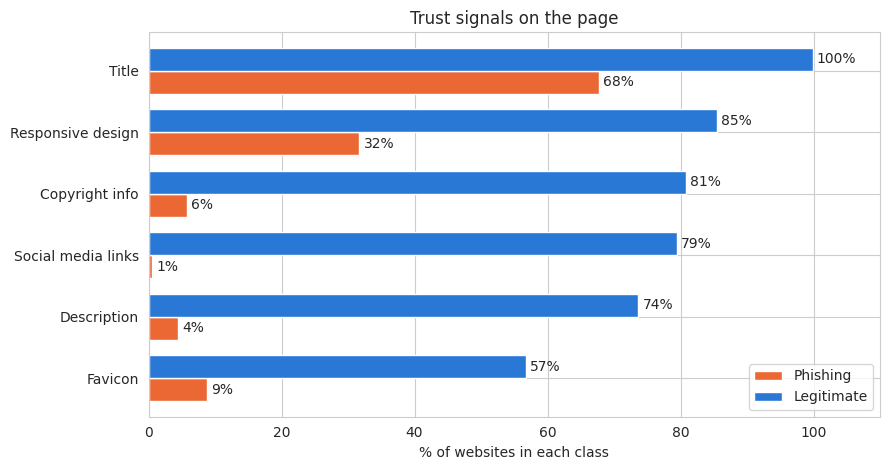

In [52]:
trust = {"HasTitle": "Title", "HasFavicon": "Favicon", "HasDescription": "Description",
         "HasCopyrightInfo": "Copyright info", "HasSocialNet": "Social media links",
         "IsResponsive": "Responsive design"}

pct = df_clean.groupby("label_name")[list(trust)].mean().T[ORDER] * 100
pct = pct.rename(index=trust).sort_values("Legitimate")

ax = pct.plot(kind="barh", color=PALETTE, width=0.75, figsize=(9, 4.8))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f%%", padding=3)
ax.set_xlim(0, 110)
ax.set_xlabel("% of websites in each class")
ax.set_title("Trust signals on the page")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Insights:**
- The largest gap is in **social media links**: only **under 1%** of phishing pages link to social
  media, compared to **79%** of legitimate pages. Copyright info (**6%** vs **81%**) and a
  description (**4%** vs **74%**) show similar gaps.
- A likely reason is that these elements take effort to build and add little to a page
  whose only goal is to collect data.

As expected in Step 2, trust signals are much more common on legitimate websites.

In [53]:
title_status = df_clean["HasTitle"].map({0: "No title", 1: "Has title"})
(pd.crosstab(title_status, df_clean["label_name"], normalize="index") * 100).round(1)[ORDER]

label_name,Phishing,Legitimate
HasTitle,,
Has title,33.6,66.4
No title,99.5,0.5


In Step 4.1, I expected that a missing title could be a sign of phishing. This is confirmed:
**99.5%** of pages without a title are phishing, compared to **33.6%** of pages that have one.
Keeping these rows in Data Cleaning preserved one of the strongest patterns in the dataset.

### 5.7 Sensitive elements
**Question 5:** Are password fields, hidden fields, and keywords like "bank", "pay" and
"crypto" more common on phishing pages?

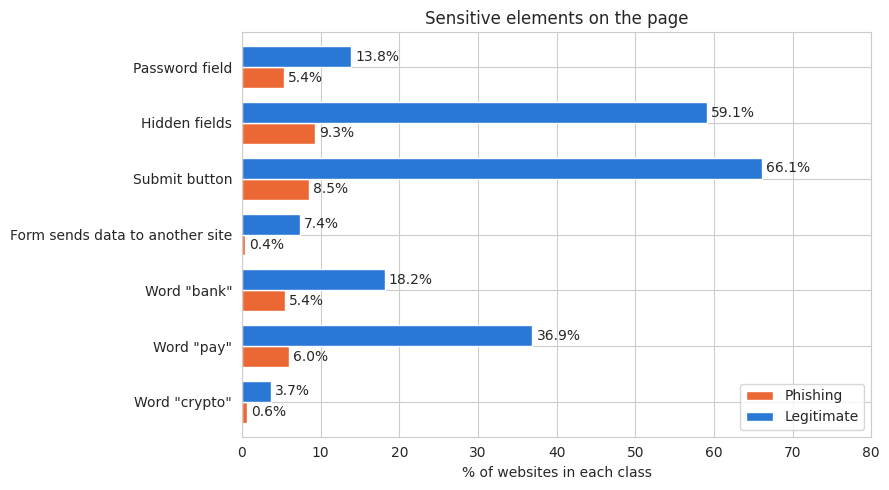

In [54]:
sensitive = {"HasPasswordField":      "Password field",
             "HasHiddenFields":       "Hidden fields",
             "HasSubmitButton":       "Submit button",
             "HasExternalFormSubmit": "Form sends data to another site",
             "HasBankKeyword":        'Word "bank"',
             "HasPayKeyword":         'Word "pay"',
             "HasCryptoKeyword":      'Word "crypto"'}

pct = df_clean.groupby("label_name")[list(sensitive)].mean().T[ORDER] * 100
pct = pct.rename(index=sensitive)[::-1]   # first feature at the top

ax = pct.plot(kind="barh", color=PALETTE, width=0.75, figsize=(9, 5))
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", padding=3)
ax.set_xlim(0, 80)
ax.set_xlabel("% of websites in each class")
ax.set_title("Sensitive elements on the page")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Result:** contrary to the expectation in Step 2, every sensitive element is **more common
on legitimate websites**. For example, **13.8%** of legitimate pages have a password field,
compared to only **5.4%** of phishing pages, and **36.9%** mention "pay" compared to **6.0%**.

However, 5.6 showed that legitimate pages are much larger (median **1,105** lines of code vs **12**).
A larger page simply has more room for forms, buttons and words. To check whether page size
explains this result, I compared pages **of similar size**.

Number of websites in each group:
label_name       Phishing  Legitimate
NoOfLinesOfCode                      
≤101                77332           0
102–300             20127        9104
301–1,000            2920       52343
1,000+                280       73403


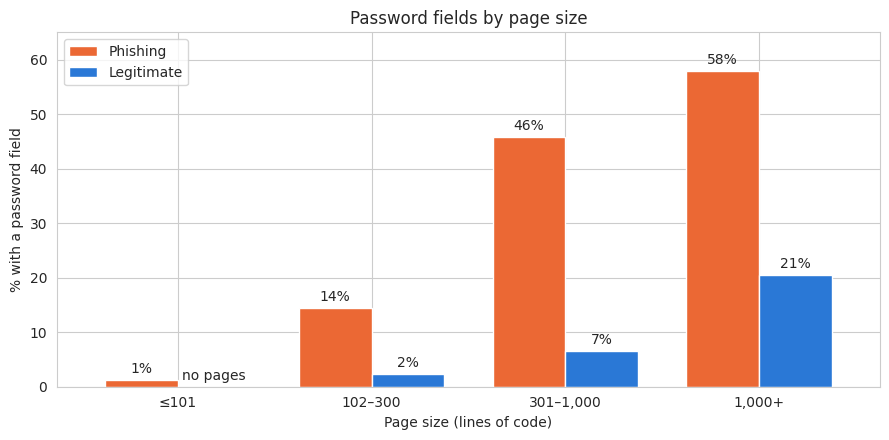

In [55]:
size_band = pd.cut(df_clean["NoOfLinesOfCode"], bins=[0, 101, 300, 1000, np.inf],
                   labels=["≤101", "102–300", "301–1,000", "1,000+"])

print("Number of websites in each group:")
print(pd.crosstab(size_band, df_clean["label_name"])[ORDER])

by_size = df_clean.groupby([size_band, "label_name"], observed=True)["HasPasswordField"].mean().unstack()[ORDER] * 100

ax = by_size.plot(kind="bar", color=PALETTE, width=0.75, rot=0, figsize=(9, 4.5))
for bars, name in zip(ax.containers, ORDER):
    labels = [f"{v:.0f}%" if pd.notna(v) else "no pages" for v in by_size[name]]
    ax.bar_label(bars, labels=labels, padding=3)
ax.set_ylim(0, 65)
ax.set_xlabel("Page size (lines of code)")
ax.set_ylabel("% with a password field")
ax.set_title("Password fields by page size")
ax.legend(title="")
plt.tight_layout()
plt.show()

**Insights:** when pages of similar size are compared, the pattern **reverses**. In every size
group that has both classes, phishing pages have password fields **far more often** than
legitimate pages, for example **46%** vs **7%** for pages with 301–1,000 lines.

The overall result was misleading because most phishing pages are tiny (**77,332** have 101
lines or fewer), and a tiny page rarely has any form at all. Among phishing pages that are
large enough to contain a form, about half ask for a password, which fits their goal of
stealing login details.

*Note: only **280** phishing pages have 1,000+ lines, so that group is small.*

### 5.8 Top-level domains
6. **Top-level domains:** Which endings (`.com`, `.org`, `.app`, ...) have the highest share of phishing websites?

Most of the **570** TLD values are rare (**467** have fewer than 100 websites), so I explored
them in two ways: by type, using the 6 types from Step 4.5 so no website is left out, and by
individual TLD, showing only TLDs with at least 1,000 websites, since percentages from very
small groups can be misleading.

                      Values  Websites  Phishing
TLDType                                         
Restricted                 4      3479       0.1
Classic generic            5    140311      35.8
Country code             231     68925      42.1
New generic              323     22146      93.8
IP address (no TLD)        1       607     100.0
Non-Latin (Punycode)       6        41     100.0


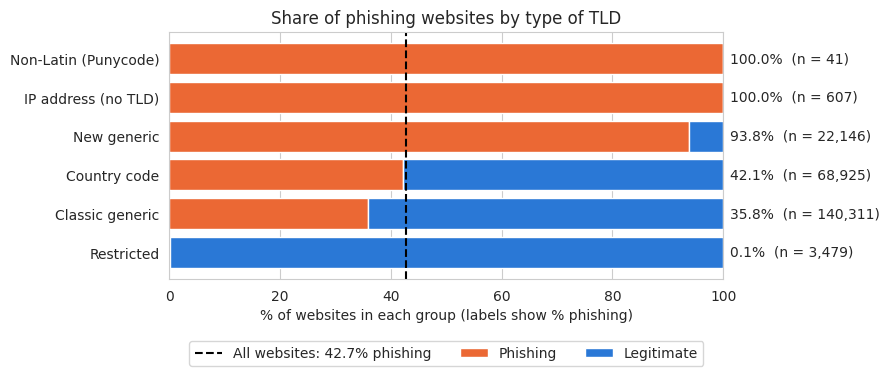

In [56]:
phishing = df_clean["label"] == 0

type_stats = pd.DataFrame({"Values":   df_clean.groupby("TLDType")["TLD"].nunique(),
                           "Websites": df_clean["TLDType"].value_counts(),
                           "Phishing": phishing.groupby(df_clean["TLDType"]).mean() * 100})
type_stats = type_stats.sort_values("Phishing").round(1)
print(type_stats)

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(type_stats.index, type_stats["Phishing"], color=PALETTE["Phishing"], label="Phishing")
bars = ax.barh(type_stats.index, 100 - type_stats["Phishing"], left=type_stats["Phishing"],
               color=PALETTE["Legitimate"], label="Legitimate")
ax.bar_label(bars, labels=[f"{p:.1f}%  (n = {n:,})" for p, n in
                           zip(type_stats["Phishing"], type_stats["Websites"])], padding=5)
ax.axvline(phishing.mean() * 100, color="black", linestyle="--",
           label=f"All websites: {phishing.mean() * 100:.1f}% phishing")
ax.set_xlim(0, 100)
ax.set_xlabel("% of websites in each group (labels show % phishing)")
ax.set_title("Share of phishing websites by type of TLD")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=3)
plt.tight_layout()
plt.show()

**Insights (TLD types):**
- **New generic TLDs** (`.app`, `.dev`, `.top`, ...) are **93.8% phishing**, more than double
  the average of 42.7%.
- **Restricted TLDs** (`.gov`, `.edu`, `.mil`, `.int`) are almost never phishing (**0.1%**),
  since only verified organizations can register them.
- **Classic generic** (35.8%) and **country code** TLDs (42.1%) are close to the average.
- **IP addresses** and **non-Latin (Punycode) TLDs** are **100% phishing**, but together they
  cover only 648 websites.

TLDs in the dataset: 570
TLDs with 1,000+ websites: 30


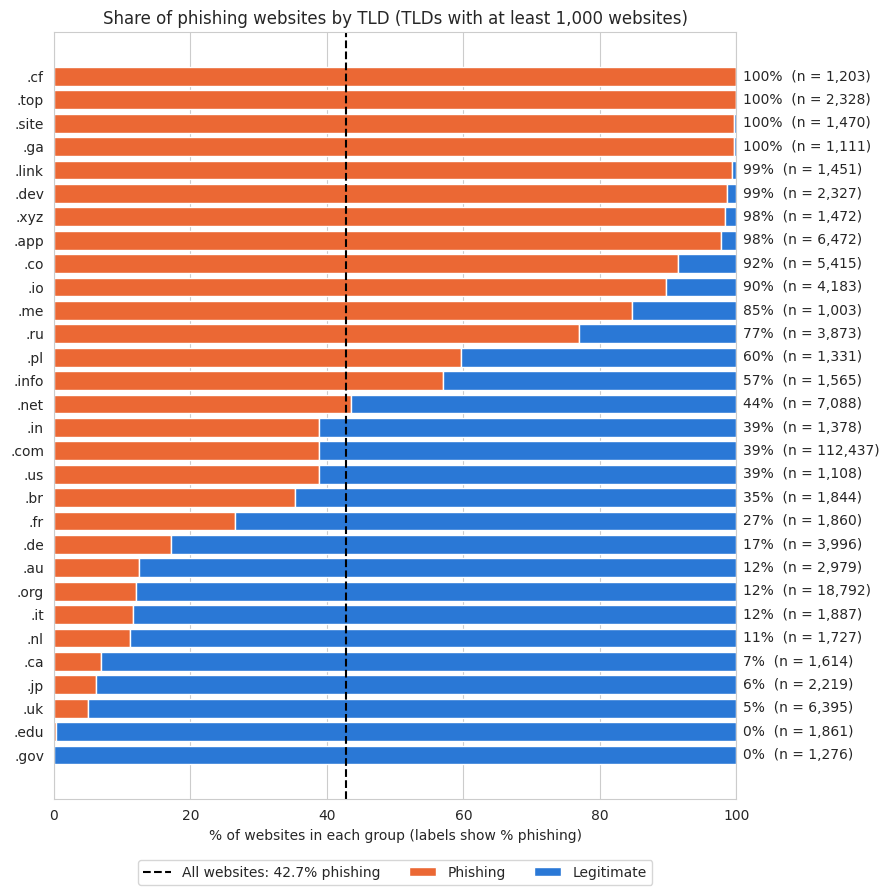

In [57]:
tld_stats = pd.DataFrame({"Websites": df_clean["TLD"].value_counts(),
                          "Phishing": phishing.groupby(df_clean["TLD"]).mean() * 100})
tld_stats = tld_stats[tld_stats["Websites"] >= 1000].sort_values("Phishing").round(1)
print("TLDs in the dataset:", df_clean["TLD"].nunique())
print("TLDs with 1,000+ websites:", len(tld_stats))

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh("." + tld_stats.index, tld_stats["Phishing"], color=PALETTE["Phishing"], label="Phishing")
bars = ax.barh("." + tld_stats.index, 100 - tld_stats["Phishing"], left=tld_stats["Phishing"],
               color=PALETTE["Legitimate"], label="Legitimate")
ax.bar_label(bars, labels=[f"{p:.0f}%  (n = {n:,})" for p, n in
                           zip(tld_stats["Phishing"], tld_stats["Websites"])], padding=5)
ax.axvline(phishing.mean() * 100, color="black", linestyle="--",
           label=f"All websites: {phishing.mean() * 100:.1f}% phishing")
ax.set_xlim(0, 100)
ax.set_xlabel("% of websites in each group (labels show % phishing)")
ax.set_title("Share of phishing websites by TLD (TLDs with at least 1,000 websites)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.07), ncol=3)
plt.tight_layout()
plt.show()

Many phishing websites on high-risk TLDs use free hosting platforms, so I checked what share of their phishing websites are hosted on each platform.

In [58]:
hosting = {"app": "web.app", "dev": "workers.dev", "co": "repl.co", "io": "ipfs.io"}

for tld, platform in hosting.items():
    phish_tld = df_clean[(df_clean["TLD"] == tld) & phishing]
    share = phish_tld["Domain"].str.endswith(platform).mean() * 100
    print(f".{tld}: {share:.0f}% of {len(phish_tld):,} phishing websites are on {platform}")

.app: 90% of 6,332 phishing websites are on web.app
.dev: 62% of 2,294 phishing websites are on workers.dev
.co: 76% of 4,957 phishing websites are on repl.co
.io: 48% of 3,751 phishing websites are on ipfs.io


**Insights (individual TLDs):**
- **Highest risk:** 8 TLDs are **98–100% phishing**: `.cf`, `.top`, `.site`, `.ga`, `.link`,
  `.dev`, `.xyz` and `.app`. Most of these are new generic TLDs, which are often cheap or free
  to register.
- **`.co` and `.io`** are country codes (Colombia and the British Indian Ocean Territory), but
  they are widely used as generic domains and are around **90% phishing**.
- **Free hosting platforms:** many phishing websites on these TLDs are hosted on free
  platforms: Firebase (`web.app`, **90%** of phishing on `.app`), Replit (`repl.co`, **76%**),
  Cloudflare (`workers.dev`, **62%**) and IPFS (`ipfs.io`, **48%**). These are free, quick to
  set up, and provide HTTPS automatically.
- **`.com`** holds almost half of all websites (112,437), and its phishing share (39%) is close
  to the average, so a `.com` domain alone says little about a site.
- **Lowest risk:** `.gov` (0%), `.edu` (0.3%), and many country TLDs such as `.uk` (5%),
  `.jp` (6%) and `.ca` (7%).

As expected in Step 2, some TLDs carry a much higher phishing share than others.

### 5.9 Outliers by label


In Step 4.3, all outliers were kept, and I expected them to be linked to the label. Here I
check this: for each feature, I took the websites with unusually **high** values (above the
upper IQR limit) and measured what share of them are phishing. Low outliers were not used,
since only 4 features have them (for example `URLCharProb` and `NoOfSubDomain`), and most
of these are phishing too. Only features with at least 500 outliers are shown.

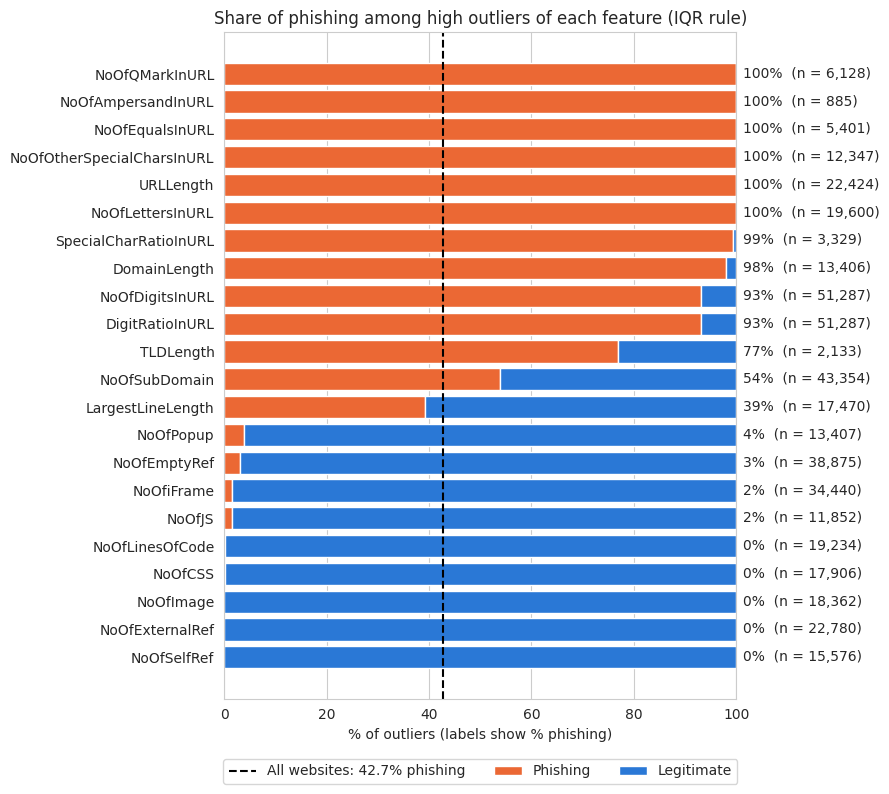

In [59]:
num_cols = df_clean.select_dtypes(include="number").columns.drop("label")
continuous_cols = [c for c in num_cols if df_clean[c].nunique() > 2]

outlier_stats = {}
for col in continuous_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    is_out = df_clean[col] > q3 + 1.5 * (q3 - q1)
    if is_out.sum() >= 500:
        outlier_stats[col] = {"Outliers": is_out.sum(), "Phishing": phishing[is_out].mean() * 100}

outlier_stats = pd.DataFrame(outlier_stats).T.sort_values("Phishing").round(1)

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(outlier_stats.index, outlier_stats["Phishing"], color=PALETTE["Phishing"], label="Phishing")
bars = ax.barh(outlier_stats.index, 100 - outlier_stats["Phishing"], left=outlier_stats["Phishing"],
               color=PALETTE["Legitimate"], label="Legitimate")
ax.bar_label(bars, labels=[f"{p:.0f}%  (n = {n:,.0f})" for p, n in
                           zip(outlier_stats["Phishing"], outlier_stats["Outliers"])], padding=5)
ax.axvline(phishing.mean() * 100, color="black", linestyle="--",
           label=f"All websites: {phishing.mean() * 100:.1f}% phishing")
ax.set_xlim(0, 100)
ax.set_xlabel("% of outliers (labels show % phishing)")
ax.set_title("Share of phishing among high outliers of each feature (IQR rule)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
plt.tight_layout()
plt.show()

In [60]:
for col in ["URLLength", "NoOfLinesOfCode", "LargestLineLength"]:
    top = df_clean.nlargest(3, col)[["URL", col, "label_name"]]
    top["URL"] = top["URL"].str[:60]   # shorten long URLs
    print(f"\nTop 3 by {col}:")
    print(top.to_string())


Top 3 by URLLength:
                                                                 URL  URLLength label_name
102883  https://xwebhostapp.github.io/freehost//#eyj2zxjzaw9uijoimc4       6097   Phishing
9650    https://b4e921f0.sso-mailsrvr-4344e5teed.pages.dev/support/?       5794   Phishing
150753  https://bodhicardstech.com/beta/wx%20qz%20xx%20ww%20qxz%20we       4274   Phishing

Top 3 by NoOfLinesOfCode:
                                URL  NoOfLinesOfCode  label_name
8376   https://www.atlanticoline.pt           442666  Legitimate
82167        https://www.audible.de           440155  Legitimate
60838     https://www.audible.co.uk           422798  Legitimate

Top 3 by LargestLineLength:
                                                                 URL  LargestLineLength label_name
162755  https://royal-flower-0de9.ylr2144t.workers.dev/ca260fb0-1d74           13975732   Phishing
174342  https://royal-flower-0de9.ylr2144t.workers.dev/e0cc7751-357d           13975732   Phishing
21

**Insights:** the outliers mostly split into two groups:
- **URL-based outliers are phishing.** Websites with unusually long URLs, long domains, or
  many digits, letters and special characters (`?`, `=`, `&`) are **93–100% phishing**. For
  example, the longest URL (6,097 characters) is a phishing page on `github.io` carrying a
  long encoded string.
- **Page-content outliers are legitimate.** Websites with unusually many lines of code,
  images, CSS files, scripts or links (including popups and iframes) are **96–100% legitimate**.
  The largest pages (over 400,000 lines of code) belong to sites such as `audible.de`.
- **A few features are mixed**, such as `LargestLineLength` (**39%** phishing) and
  `NoOfSubDomain` (**54%**). The longest single line, almost 14 million characters, is a
  phishing page on `workers.dev` with only 43 lines of code, which suggests its code was
  packed into one line to hide it.

This confirms the expectation from Step 4.3: the outliers are not noise, but some of the
clearest differences between the two classes. Removing them would have hidden these patterns.

## Multivariate Analysis

### 5.10 URL length vs. page size

The previous sections showed that phishing URLs tend to be longer (5.4) and phishing pages
much smaller (5.6). This scatter plot looks at both features together. To keep the chart
readable, it shows a random sample of 5,000 websites from each class.

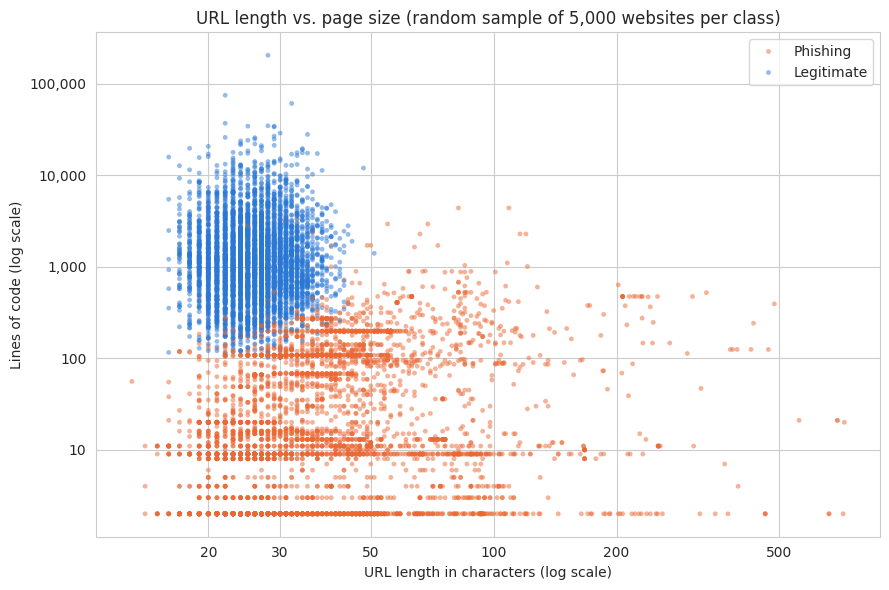

In [61]:
sample = df_clean.groupby("label_name").sample(n=5000, random_state=42)
sample = sample.sample(frac=1, random_state=42)   # shuffle so neither class is drawn on top

fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=sample, x="URLLength", y="NoOfLinesOfCode", hue="label_name",
                hue_order=ORDER, palette=PALETTE, s=12, alpha=0.5, linewidth=0, ax=ax)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([20, 30, 50, 100, 200, 500])
ax.minorticks_off()
ax.xaxis.set_major_formatter(THOUSANDS)
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_xlabel("URL length in characters (log scale)")
ax.set_ylabel("Lines of code (log scale)")
ax.set_title("URL length vs. page size (random sample of 5,000 websites per class)")
ax.legend(title="")
plt.tight_layout()
plt.show()

In [62]:
phishing_loc = df_clean.loc[phishing, "NoOfLinesOfCode"]

overlap = phishing_loc >= 102   # 102 = smallest legitimate page
print("Phishing pages as large as legitimate pages:", overlap.sum())
print("Share of all phishing pages:", round(overlap.mean() * 100, 1), "%")

print("\nMost common page sizes among phishing pages:")
print(phishing_loc.value_counts().head(3))

Phishing pages as large as legitimate pages: 23327
Share of all phishing pages: 23.2 %

Most common page sizes among phishing pages:
NoOfLinesOfCode
2      26315
9      10928
108     6257
Name: count, dtype: int64


In [63]:
legit_length = df_clean.loc[~phishing, "URLLength"]
print("\nLegitimate URLs with 20-40 characters:", round(legit_length.between(20, 40).mean() * 100, 1), "%")
print("Longest legitimate URL:", legit_length.max(), "characters")


Legitimate URLs with 20-40 characters: 93.0 %
Longest legitimate URL: 57 characters


**Insights:**
- **Legitimate websites form one tight cluster:** short URLs (**93%** are 20–40 characters)
  and large pages.
- **Phishing websites are spread out:** small pages at any URL length, plus all of the very
  long URLs (every URL over 100 characters is phishing). The horizontal lines of dots are
  many pages with exactly the same size: **26,315** phishing pages have exactly 2 lines of
  code and **10,928** have 9, which suggests they are copies of the same simple page or template.
- **Overlap:** **23.2%** of phishing pages are as large as legitimate pages, so page size
  alone cannot identify them, and other features are needed.

### 5.11 Correlation analysis
**Question 7:** Which features are most related to the label?

I used **Spearman** correlation instead of the default Pearson. Pearson only measures linear
relationships and is strongly affected by extreme values, while Spearman compares the
**ranks** of values, so it works better for the skewed features in this dataset. For
example, `NoOfLinesOfCode` has a Pearson correlation of only 0.27 with the label, but a
Spearman correlation of 0.84.

Since `label` is 1 for legitimate and 0 for phishing, a **positive** correlation means the
feature is higher on **legitimate websites**, and a **negative** one means it is higher on
**phishing websites**.

In [64]:
print("Pearson correlation of NoOfLinesOfCode with label:", round(df_clean["NoOfLinesOfCode"].corr(df_clean["label"]), 2))
print("URLSimilarityIndex values of legitimate websites:", df_clean.loc[~phishing, "URLSimilarityIndex"].unique())

Pearson correlation of NoOfLinesOfCode with label: 0.27
URLSimilarityIndex values of legitimate websites: [100.]


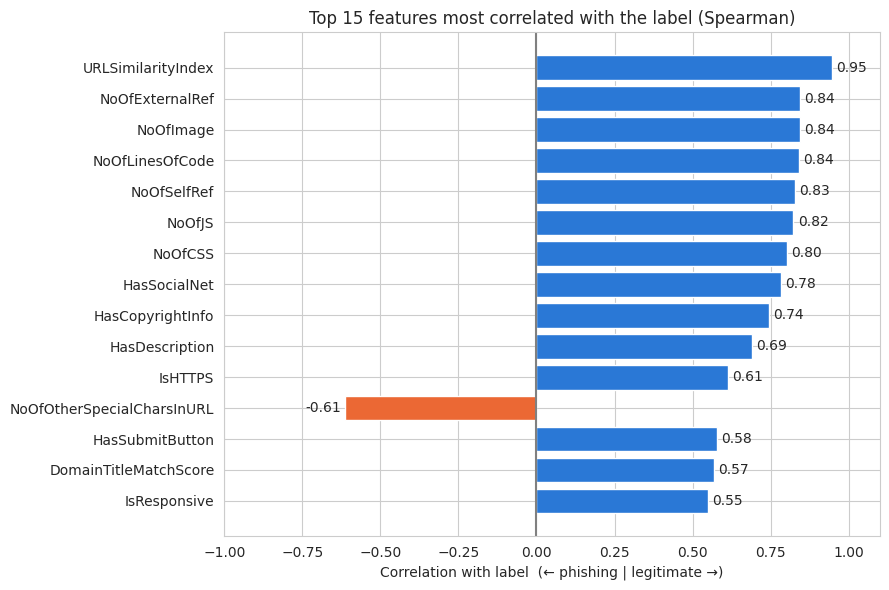

In [65]:
corr_with_label = df_clean.select_dtypes(include="number").corr(method="spearman")["label"].drop("label")
top = corr_with_label[corr_with_label.abs().sort_values(ascending=False).head(15).index]

colors = [PALETTE["Legitimate"] if v > 0 else PALETTE["Phishing"] for v in top]
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(top.index[::-1], top[::-1], color=colors[::-1])
ax.bar_label(bars, fmt="%.2f", padding=3)
ax.axvline(0, color="gray")
ax.set_xlim(-1, 1.1)
ax.set_xlabel("Correlation with label  (← phishing | legitimate →)")
ax.set_title("Top 15 features most correlated with the label (Spearman)")
plt.tight_layout()
plt.show()

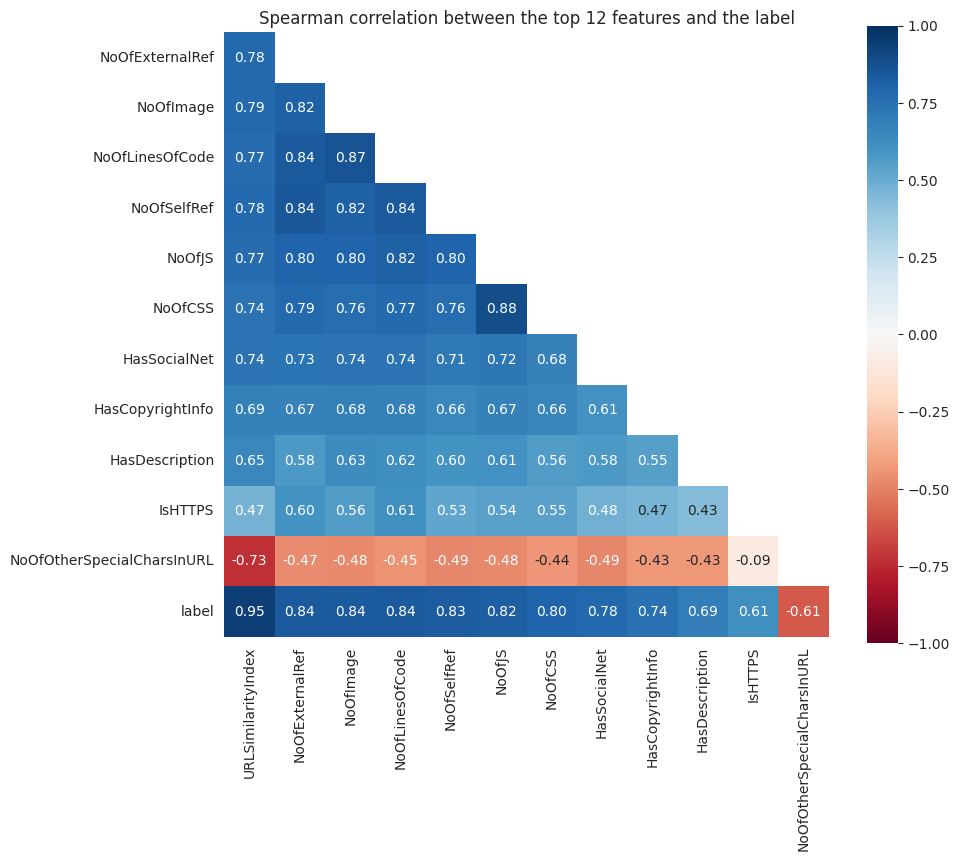

In [66]:
top_features = top.index[:12].tolist() + ["label"]
corr = df_clean[top_features].corr(method="spearman")
corr = corr.iloc[1:, :-1]                             # drop the empty first row and last column
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # hide the repeated upper half

fig, ax = plt.subplots(figsize=(10, 8.5))
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True, ax=ax)
ax.set_title("Spearman correlation between the top 12 features and the label")
ax.grid(False)
plt.tight_layout()
plt.show()

**Insights:**
- `URLSimilarityIndex` is the strongest feature (**0.95**). It measures how similar a URL is
  to known legitimate URLs. Every legitimate website in the dataset scores exactly 100, which
  suggests the legitimate websites come from the same reference list used to compute this
  score. This makes the feature very strong, but partly circular.
- **Page size** is the next strongest group (**0.80–0.84**): external links, images, lines of
  code, self-references, scripts and CSS files are all much higher on legitimate websites.
- **Trust signals** follow: social media links (**0.78**), copyright info (**0.74**) and
  description (**0.69**), then `IsHTTPS` (**0.61**).
- The strongest phishing feature is `NoOfOtherSpecialCharsInURL` (**−0.61**): more special
  characters in the URL point to phishing.

**Redundancy:** the page-size features are strongly correlated with each other (**0.76–0.88**),
because a larger page naturally has more lines, images, scripts and links. They mostly carry
the same information, so a predictive model would not need all of them.

As expected in Step 2, a small group of features separates the two classes strongly. However,
some of the strongest ones (`URLSimilarityIndex`, `IsHTTPS`) are affected by how the
legitimate websites were selected (see 5.4 and 5.5).

# **Step 6: Insights Summary**

## Expectations vs. results

| Expectation (Step 2) | Result |
|---|---|
| Phishing URLs are longer, with more digits and special characters | ✅ Median length **34** vs **26**; **47%** of phishing URLs contain digits vs **3%** of legitimate ones |
| Legitimate websites almost always use HTTPS | ✅ **100%** of legitimate vs **49%** of phishing (partly due to data collection), but **1 in 4** HTTPS websites is still phishing |
| Phishing pages are smaller and simpler | ✅ Median of **12** lines of code vs **1,105** |
| Trust signals are more common on legitimate websites | ✅ Social media links on **79%** of legitimate pages vs **under 1%** of phishing |
| Some TLDs have a much higher phishing share | ✅ New generic TLDs are **93.8%** phishing; `.gov` and `.edu` almost **0%** |
| A small group of features separates the classes strongly | ✅ Correlations up to **0.95**, but partly affected by how the data was collected |
| Sensitive elements are more common on phishing pages (Question 5) | ❌ overall, ✅ after comparing pages of similar size |



## Patterns and relationships

- **Phishing pages are minimal.** **62%** have 20 lines of code or fewer, and every page this
  small is phishing.
- **URL and page features point in opposite directions:** long, complex URLs point to phishing,
  while large, content-rich pages point to legitimate websites.
- **Many phishing websites use free and cheap services:** free hosting platforms such as
  Firebase (`web.app`) and Cloudflare (`workers.dev`), which are quick to set up and come with
  HTTPS, and cheap TLDs such as `.top` and `.xyz`.
- **A missing title is a strong warning sign:** **99.5%** of pages without a title are phishing.
- **Page size hides the real pattern for sensitive elements.** Overall, password fields are
  more common on legitimate pages (**13.8%** vs **5.4%**), but among pages of similar size,
  phishing pages ask for a password **3 to 7 times** more often.
- **Page-size features are redundant:** lines of code, images, scripts and links are highly
  correlated with each other (**0.76–0.88**).



## Outliers

- **Outliers are real values, not errors**, and they are strongly linked to the label: high
  URL-based values are **93–100%** phishing, and high page-content values are **96–100%**
  legitimate.
- **Notable cases:** a **6,097**-character phishing URL, legitimate pages with over
  **400,000** lines of code, and a phishing page with a single line of almost **14 million**
  characters.

## Key takeaways

- **HTTPS does not mean safe.** The padlock only means the connection is encrypted, and about
  **1 in 4** HTTPS websites in this dataset is phishing.
- **No single feature is enough.** The rarest signs (IP addresses, obfuscation, Punycode) are
  **100%** phishing but catch only **1.3%** of phishing websites, and **23%** of phishing pages
  are as large as legitimate ones.
- **Simple checks go a long way:** an unusual TLD, a missing title, no social media or
  copyright information, and a long URL with many special characters are all strong warning
  signs.
- **Results should be read with care:** all legitimate websites are homepages
  (`https://www.domain`) with at least 102 lines of code, and all of them have a
  `URLSimilarityIndex` of exactly 100. So some differences come from how the dataset was
  built, not only from how phishing websites behave.